In [5]:
import pandas as pd
import numpy as np

**1)An airline tracks flight delays (in minutes) for 20 flights. 
Analyze the flight delays to calculate percentiles, detect outliers, and evaluate the overall distribution.**

In [2]:
data1 = [15, 30, 45, 20, 25, 100, 5, 60, 35, 50, 
          120, 80, 10, 75, 90, 200, 55, 40, 70, 150]

In [3]:
dataset1 = pd.DataFrame(data1)

In [7]:
percentail_10 =  np.percentile(dataset1,10)
percentail_25 =  np.percentile(dataset1,25)
percentail_50 =  np.percentile(dataset1,50)
percentail_75 =  np.percentile(dataset1,75)
percentail_90 = np.percentile(dataset1,90)
print("Percentails:",percentail_10,percentail_25,percentail_50,percentail_75,percentail_90)
IQR = percentail_75 - percentail_25
print("IQR",IQR)

Percentails: 14.5 28.75 52.5 82.5 123.00000000000004
IQR 53.75


In [8]:
rule = 1.5 * IQR
Lower_Bound = percentail_25 - rule
print("Lower_Bound", Lower_Bound)
Upper_Bound = percentail_75 + rule
print("Upper_Bound", Upper_Bound)

Lower_Bound -51.875
Upper_Bound 163.125


In [13]:
def outlier_column(dataset1):
      lesser = []
      greater = []
      for columnName in dataset1:
          if columnName < Lower_Bound:
             lesser.append(columnName)
    
          if columnName > Upper_Bound:
            greater.append(columnName)           
      return lesser, greater


In [14]:
lesser, greater = outlier_column(dataset1[0])

In [15]:
lesser
greater

[200]

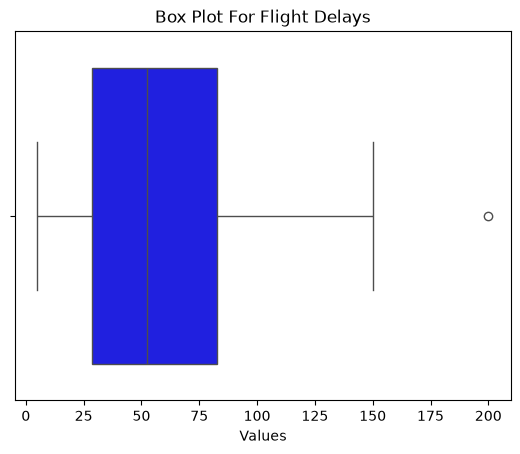

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=dataset1[0], color='blue')

plt.title('Box Plot For Flight Delays')
plt.xlabel('Values')
plt.show()

**2)A company wants to analyze the salary distribution of its employees to understand the central tendency 
and determine whether the data is skewed.**

In [18]:
salaries = [30000, 32000, 35000, 37000, 40000, 42000, 45000, 47000, 50000, 55000,
            60000, 62000, 65000, 67000, 70000, 72000, 75000, 80000, 85000, 90000]

In [20]:
dataset2 = pd.DataFrame(salaries)

In [24]:
print("Mean Salary: ",float(dataset2[0].mean()))

Mean Salary:  56950.0


In [25]:
print("Median Salary: ",float(dataset2[0].median()))

Median Salary:  57500.0


In [27]:
print("Mode Salary: ",float(dataset2[0].mode()[0]))

Mode Salary:  30000.0


Median > Mean so it is left skew

In [32]:
print("Skew: ",float(dataset2[0].skew()))

Skew:  0.1788044808612648


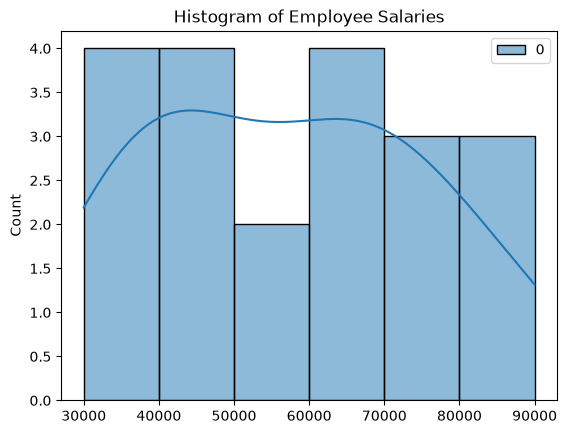

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(dataset2, kde=True)
plt.title("Histogram of Employee Salaries")
plt.show()

**3)A school wants to analyze the exam performance of students across three subjects: Mathematics, Science, and English. 
    How can Data Science concepts be applied to understand their performance?**

In [35]:
data = {
    'Student': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'],
    'Mathematics': [85, 78, 92, 88, 70, 95, 60, 80, 90, 76],
    'Science': [80, 85, 88, 70, 75, 92, 55, 82, 89, 78],
    'English': [78, 74, 85, 80, 68, 90, 50, 77, 83, 72]
}

In [37]:
dataset3 = pd.DataFrame(data)
dataset3

,Student,Mathematics,Science,English
0,A,85,80,78
1,B,78,85,74
2,C,92,88,85
3,D,88,70,80
4,E,70,75,68
5,F,95,92,90
6,G,60,55,50
7,H,80,82,77
8,I,90,89,83
9,J,76,78,72


**Descriptive Analysis**

In [38]:
dataset3.describe()

,Mathematics,Science,English
count,10.000000,10.000000,10.000000
mean,81.400000,79.400000,75.700000
std,10.844353,10.895463,11.086027
min,60.000000,55.000000,50.000000
25%,76.500000,75.750000,72.500000
50%,82.500000,81.000000,77.500000
75%,89.500000,87.250000,82.250000
max,95.000000,92.000000,90.000000


**Histogram**

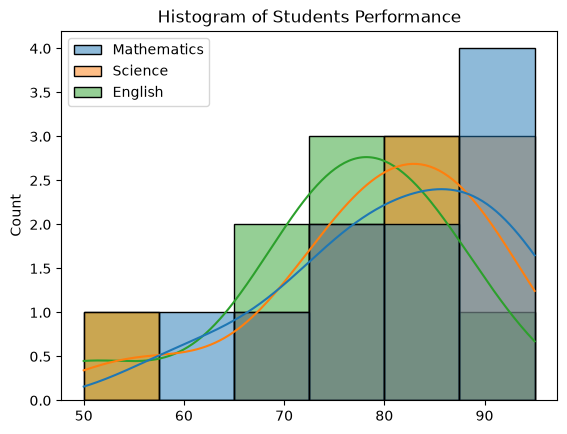

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(dataset3, kde=True)
plt.title("Histogram of Students Performance")
plt.show()

**Correlation Analysis(HeatMap)**

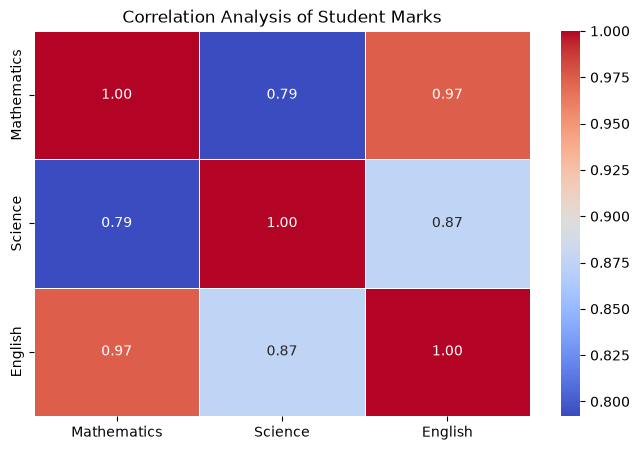

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt
correlation = dataset3[['Mathematics', 'Science', 'English']].corr()
plt.figure(figsize=(8, 5))
sns.heatmap(correlation,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5)

plt.title('Correlation Analysis of Student Marks')
plt.show()

**4)A pharmaceutical company conducted a clinical trial with two groups: one receiving medication and the other a placebo. 
How do you perform a hypothesis test to determine the effectiveness of the medication?**

In [53]:
data = {'medication_group' : [110, 115, 108, 102, 107, 99, 111, 104, 109, 101],
'placebo_group' : [120, 125, 130, 122, 128, 119, 124, 127, 123, 126] }

In [54]:
dataset = pd.DataFrame(data)

In [56]:
from scipy.stats import ttest_ind
dataset = dataset.dropna()
medication = dataset['medication_group']
placebo = dataset['placebo_group']
ttest_ind(medication,placebo)

TtestResult(statistic=np.float64(-9.201427649220966), pvalue=np.float64(3.163912817600808e-08), df=np.float64(18.0))

P-Value is greater than 0.05
Solution : Reject Null hypothesis so Accept alternate hypothesis

**5)A company conducted a customer satisfaction survey where customers rated their experience on a scale of 1 to 10. 
    Analyze the survey results to calculate descriptive statistics and visualize the distribution of customer satisfaction ratings.**

In [57]:
ratings = [8, 9, 7, 5, 6, 10, 9, 4, 7, 8, 
           6, 9, 10, 5, 8, 7, 6, 9, 10, 7]

In [59]:
dataset5 = pd.DataFrame(ratings)
dataset5

,0
0,8
1,9
2,7
3,5
4,6
5,10
6,9
7,4
8,7
9,8


In [60]:
print("Mean Rating: ",float(dataset5[0].mean()))

Mean Rating:  7.5


In [61]:
print("Median Rating: ",float(dataset5[0].median()))

Median Rating:  7.5


In [62]:
print("Mode Rating: ",float(dataset5[0].mode()[0]))

Mode Rating:  7.0


In [63]:
print("Standard Deviation: ",float(dataset5[0].std()))

Standard Deviation:  1.7917941611104424


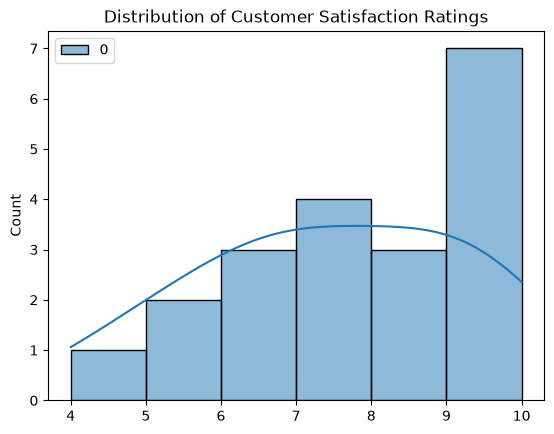

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(dataset5, kde=True)
plt.title("Distribution of Customer Satisfaction Ratings")
plt.show()